In [2]:
#Ejemplo de test de hipótesis sobre proporción
#Base de datos de salud del INDEC
#https://www.indec.gob.ar/ftp/cuadros/menusuperior/enprecosp/bases_enprecosp2011.rar
#Acomodé el archivo para que sea .csv

import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

In [4]:
# Carga de datos
archivo = 'data/BaseUsuarioENPreCoSP-2011.csv'
datos = pd.read_csv(archivo)

# Selección de datos de Gran La Plata
datos_granlaplata = datos[datos['AGL_URB'] == 6]

# Selección de personas que beben cerveza durante el fin de semana
cerveza_fin_semana = datos_granlaplata['BIBA09_01']
cerveza_fin_semana.replace({888: 0.0}, inplace=True)  # Reemplazar 888 (no bebe alcohol) con 0

/var/folders/0n/g5l4v8c52nn4wxk7hl89vk3m0000gn/T/ipykernel_5584/3389569055.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cerveza_fin_semana.replace({888: 0.0}, inplace=True)  # Reemplazar 888 (no bebe alcohol) con 0


Media: 2.43578431372549
Desviación estándar: 3.0686338329195086


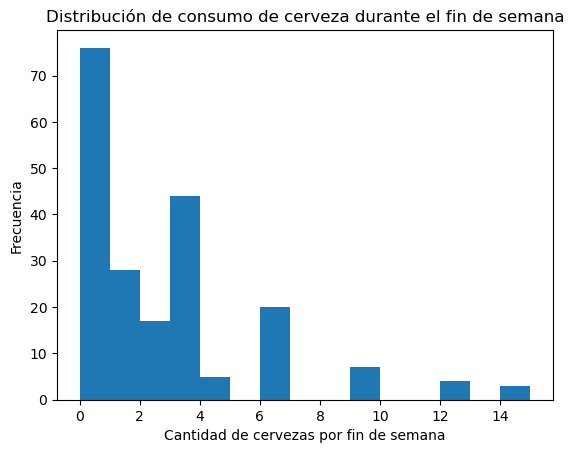

In [5]:
# Estadísticas descriptivas
print("Media:", np.mean(cerveza_fin_semana))
print("Desviación estándar:", np.std(cerveza_fin_semana))

# Gráfico
plt.figure()
plt.hist(cerveza_fin_semana, bins='auto')
plt.xlabel('Cantidad de cervezas por fin de semana')
plt.ylabel('Frecuencia')
plt.title('Distribución de consumo de cerveza durante el fin de semana')
plt.show()

In [6]:
# Eliminación de valores NA
cerveza_fin_semana_limpia = cerveza_fin_semana.dropna()
n = len(cerveza_fin_semana_limpia)
print("Número de datos sin NA:", n)

Número de datos sin NA: 204


In [7]:
# Proporción de personas que toman al menos 3 cervezas por fin de semana
x = np.sum(cerveza_fin_semana_limpia > 2)
p_obs = x / n
print("Proporción observada de personas que beben al menos 3 cervezas por fin de semana:", p_obs)
print("Proporción observada de personas que beben menos de 3 cervezas por fin de semana:", 1 - p_obs)


Proporción observada de personas que beben al menos 3 cervezas por fin de semana: 0.4264705882352941
Proporción observada de personas que beben menos de 3 cervezas por fin de semana: 0.5735294117647058


In [8]:
# Aproximación Normal a la Binomial
p0 = 0.35
sigma = np.sqrt(p0 * (1 - p0) / n)
z_0 = (p_obs - p0) / sigma
p_value = 1 - stats.norm.cdf(z_0)
print("Valor p con aproximación Normal:", p_value)

Valor p con aproximación Normal: 0.011013205995342168


In [9]:
# Test de hipótesis binomial
p_value_bin = stats.binomtest(x, n=n, p=0.35, alternative='greater')
print("Valor p con Binomial:", p_value_bin)

Valor p con Binomial: BinomTestResult(k=87, n=204, alternative='greater', statistic=0.4264705882352941, pvalue=0.01417931775277052)


In [10]:
# Cálculo del tamaño de muestra para una potencia de 0.9
alfa = 0.05  # Significancia 5%
z_alfa = stats.norm.ppf(1 - alfa, loc=0, scale=1)
beta = 0.1  # Potencia 90%
z_beta = stats.norm.ppf(1 - beta, loc=0, scale=1)
p = 0.44  # Proporción verdadera (H1)
n = ((z_alfa * np.sqrt(p0 * (1 - p0)) + z_beta * np.sqrt(p * (1 - p))) / (p - p0)) ** 2
print("Tamaño de muestra para potencia 0.9:", n)


Tamaño de muestra para potencia 0.9: 249.18048264657415
